In [1]:
!pip install -q torch transformers sentence-transformers faiss-cpu peft accelerate scipy scikit-learn matplotlib seaborn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 36.4 MB/s eta 0:00:00


In [2]:
# ── CELL 0: Fix Environment ─────────────────────────────────
!pip install -q --upgrade "torchao>=0.16.0" "peft>=0.14.0" transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 51.5 MB/s eta 0:00:00


In [12]:
import os, json, random, warnings, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional
from copy import deepcopy

import faiss
from sentence_transformers import SentenceTransformer
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM,
    get_linear_schedule_with_warmup,
)
from peft import LoraConfig, get_peft_model, TaskType
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 150
sns.set_style("whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


@dataclass
class Config:
    n_domains: int = 5
    docs_per_domain: int = 40
    qa_per_domain: int = 80
    domain_names: List[str] = field(default_factory=lambda: [
        "Human Anatomy", "Organic Chemistry", "Planetary Science",
        "Data Structures", "Immunology",
    ])
    embed_model_name: str = "sentence-transformers/all-MiniLM-L6-v2"
    embed_dim: int = 384
    top_k: int = 5
    gen_model_name: str = "google/flan-t5-small"
    lora_r: int = 8
    lora_alpha: int = 16
    lora_dropout: float = 0.05
    train_epochs: int = 3
    train_lr: float = 2e-4
    train_batch_size: int = 16
    max_src_len: int = 128
    max_tgt_len: int = 32
    replay_buffer_size: int = 200
    ewc_lambda: float = 5000.0
    fisher_samples: int = 100
    drift_window_size: int = 30
    drift_threshold: float = 0.12
    memory_cap: int = 120
    n_bootstrap: int = 1000
    ci_level: float = 0.95

CFG = Config()
print(f"Config: {CFG.n_domains} domains, {CFG.docs_per_domain} docs/domain, "
      f"{CFG.qa_per_domain} QA/domain")

Device: cuda
Config: 5 domains, 40 docs/domain, 80 QA/domain


In [4]:
DOMAIN_KNOWLEDGE = {
    "Human Anatomy": {
        "subjects": [
            "heart", "liver", "kidney", "lung", "brain", "spleen",
            "pancreas", "stomach", "femur", "humerus", "tibia",
            "cerebellum", "hippocampus", "aorta", "trachea",
        ],
        "templates": [
            ("The {subj} is located in the {fill1} region of the human body.", "locations"),
            ("The {subj} receives blood supply from the {fill1} artery.", "arteries"),
            ("The {subj} is innervated by the {fill1} nerve.", "nerves"),
            ("The primary function of the {subj} is to {fill1}.", "functions"),
            ("The {subj} weighs approximately {fill1} grams in adults.", "weights"),
            ("Damage to the {subj} can result in {fill1}.", "conditions"),
            ("The {subj} develops from the {fill1} germ layer during embryogenesis.", "germs"),
            ("The {subj} is surrounded by the {fill1} membrane.", "membranes"),
        ],
        "locations": ["thoracic", "abdominal", "cranial", "pelvic",
                       "mediastinal", "retroperitoneal", "inguinal", "cervical"],
        "arteries": ["celiac", "renal", "hepatic", "coronary", "mesenteric",
                      "pulmonary", "carotid", "subclavian"],
        "nerves": ["vagus", "phrenic", "sciatic", "median", "ulnar",
                    "recurrent laryngeal", "intercostal", "hypoglossal"],
        "functions": ["filter blood", "produce bile", "pump blood",
                       "exchange gases", "store glycogen", "produce insulin",
                       "regulate balance", "process nutrients"],
        "weights": ["250", "1500", "150", "1000", "1400", "350",
                     "80", "900", "300", "400"],
        "conditions": ["organ failure", "internal hemorrhage",
                        "metabolic dysfunction", "respiratory distress",
                        "neurological deficit", "cardiac arrest"],
        "germs": ["ectoderm", "mesoderm", "endoderm"],
        "membranes": ["pleural", "pericardial", "peritoneal", "meningeal",
                       "synovial", "mucosal"],
    },
    "Organic Chemistry": {
        "subjects": [
            "benzene", "ethanol", "acetone", "acetic acid", "toluene",
            "phenol", "aniline", "cyclohexane", "formaldehyde",
            "pyridine", "furan", "thiophene", "naphthalene",
            "acetylene", "glycerol",
        ],
        "templates": [
            ("The IUPAC name of {subj} is {fill1}.", "iupacs"),
            ("{subj} has the molecular formula {fill1}.", "formulas"),
            ("The boiling point of {subj} is {fill1} degrees Celsius.", "bps"),
            ("{subj} undergoes {fill1} reaction with common reagents.", "reactions"),
            ("The hybridization of carbon in {subj} is {fill1}.", "hybrids"),
            ("{subj} is classified as a {fill1} compound.", "classes"),
            ("The pKa of {subj} is approximately {fill1}.", "pkas"),
            ("{subj} is synthesized via the {fill1} method.", "syntheses"),
        ],
        "iupacs": ["ethanoic acid", "propan-2-one", "methylbenzene",
                    "hydroxybenzene", "phenylamine", "cyclohexane",
                    "methanal", "1,2,3-propanetriol"],
        "formulas": ["C6H6", "C2H5OH", "C3H6O", "CH3COOH", "C7H8",
                      "C6H5OH", "C6H5NH2", "C6H12"],
        "bps": ["80.1", "78.4", "56.0", "118.1", "110.6",
                 "181.7", "184.1", "80.7"],
        "reactions": ["electrophilic substitution", "nucleophilic addition",
                       "oxidation", "reduction", "Friedel-Crafts alkylation",
                       "esterification", "halogenation"],
        "hybrids": ["sp2", "sp3", "sp"],
        "classes": ["aromatic hydrocarbon", "alcohol", "ketone",
                     "carboxylic acid", "amine", "heterocyclic"],
        "pkas": ["4.76", "10.0", "4.6", "15.7", "0.8", "31.0"],
        "syntheses": ["Grignard", "Diels-Alder", "Williamson ether",
                       "Aldol condensation", "Claisen rearrangement",
                       "Fischer esterification"],
    },
    "Planetary Science": {
        "subjects": [
            "Mercury", "Venus", "Mars", "Jupiter", "Saturn",
            "Uranus", "Neptune", "Titan", "Europa", "Ganymede",
            "Ceres", "Pluto", "Enceladus", "Io", "Callisto",
        ],
        "templates": [
            ("{subj} has an orbital period of {fill1} Earth years.", "periods"),
            ("The surface temperature of {subj} is approximately {fill1} K.", "temps"),
            ("{subj} has {fill1} confirmed natural satellites.", "moons_count"),
            ("The atmospheric composition of {subj} is primarily {fill1}.", "atmos"),
            ("{subj} has a mean radius of {fill1} km.", "radii"),
            ("The gravitational acceleration on {subj} is {fill1} m/s^2.", "gravs"),
            ("{subj} was first visited by the {fill1} spacecraft.", "missions"),
            ("The albedo of {subj} is approximately {fill1}.", "albedos"),
        ],
        "periods": ["0.24", "0.62", "1.88", "11.86", "29.46",
                     "84.01", "164.8", "15.9", "3.55", "7.15"],
        "temps": ["440", "737", "210", "165", "134",
                   "76", "72", "94", "102", "110"],
        "moons_count": ["0", "0", "2", "95", "146",
                         "28", "16", "1", "0", "4"],
        "atmos": ["carbon dioxide", "hydrogen and helium",
                   "nitrogen and methane", "sulfur dioxide",
                   "water vapor plumes", "trace argon"],
        "radii": ["2440", "6052", "3390", "69911", "58232",
                   "25362", "24622", "2575", "1561", "2634"],
        "gravs": ["3.7", "8.87", "3.72", "24.79", "10.44",
                   "8.87", "11.15", "1.35", "1.31", "1.24"],
        "missions": ["Mariner 10", "Venera 7", "Viking 1", "Pioneer 10",
                      "Cassini", "Voyager 2", "New Horizons", "Galileo"],
        "albedos": ["0.12", "0.75", "0.25", "0.52", "0.47",
                     "0.51", "0.41", "0.22", "0.67", "0.63"],
    },
    "Data Structures": {
        "subjects": [
            "binary search tree", "hash table", "B-tree",
            "red-black tree", "AVL tree", "skip list",
            "trie", "heap", "disjoint set", "segment tree",
            "Fenwick tree", "Bloom filter", "LRU cache",
            "priority queue", "adjacency list",
        ],
        "templates": [
            ("The average time complexity of search in a {subj} is O({fill1}).", "tcs"),
            ("A {subj} uses {fill1} space complexity.", "spaces"),
            ("The {subj} is implemented using {fill1}.", "impls"),
            ("A {subj} supports {fill1} operations efficiently.", "ops_list"),
            ("The best use case for a {subj} is {fill1}.", "usecases"),
            ("A {subj} was invented by {fill1}.", "inventors"),
            ("The {subj} maintains {fill1} as its invariant.", "properties"),
            ("Deletion in a {subj} requires {fill1} to restore balance.", "del_ops"),
        ],
        "tcs": ["log n", "1", "n", "n log n", "alpha(n)"],
        "spaces": ["O(n)", "O(n log n)", "O(m + n)"],
        "impls": ["linked nodes with parent pointers", "array-based hashing",
                   "balanced tree rotations", "array with heap property",
                   "bit arrays with multiple hash functions"],
        "ops_list": ["insert, delete, and search", "merge and split",
                      "range query and point update", "union and find",
                      "push and pop"],
        "usecases": ["database indexing", "spell checking",
                      "network routing", "memory management",
                      "priority scheduling", "caching web pages"],
        "inventors": ["Adelson-Velskii and Landis", "Bayer and McCreight",
                       "Pugh", "Burton Bloom", "Tarjan"],
        "properties": ["height balance", "coloring constraints",
                        "heap ordering", "sorted order", "BFS traversal order"],
        "del_ops": ["rotation", "rebalancing", "cascading cuts",
                     "sifting down", "rehashing"],
    },
    "Immunology": {
        "subjects": [
            "T cell", "B cell", "macrophage", "dendritic cell",
            "natural killer cell", "neutrophil", "mast cell",
            "IgG antibody", "IgM antibody", "IgA antibody",
            "complement system", "interferon", "interleukin-2",
            "TNF-alpha", "MHC class II",
        ],
        "templates": [
            ("The {subj} is produced primarily in the {fill1}.", "organs"),
            ("The {subj} expresses the surface marker {fill1}.", "markers"),
            ("The {subj} plays a key role in {fill1}.", "roles"),
            ("Deficiency of {subj} leads to {fill1}.", "diseases"),
            ("The {subj} is activated by {fill1}.", "activators"),
            ("The half-life of {subj} in serum is approximately {fill1} days.", "halflives"),
            ("The {subj} migrates to the {fill1} during inflammation.", "locations_list"),
            ("The {subj} recognizes antigens via {fill1}.", "receptors"),
        ],
        "organs": ["bone marrow", "thymus", "spleen", "lymph nodes",
                    "Peyer's patches", "mucosal tissue"],
        "markers": ["CD4", "CD8", "CD19", "CD14", "CD56",
                     "CD3", "CD16", "CD25"],
        "roles": ["cell-mediated immunity", "antibody production",
                   "phagocytosis", "antigen presentation",
                   "innate immune surveillance", "allergic response",
                   "opsonization"],
        "diseases": ["severe combined immunodeficiency",
                      "chronic granulomatous disease",
                      "selective IgA deficiency", "autoimmune hemolysis",
                      "complement deficiency syndrome"],
        "activators": ["pathogen-associated molecular patterns",
                        "cytokine signaling", "antigen-MHC binding",
                        "toll-like receptor engagement",
                        "complement cascade products"],
        "halflives": ["21", "5", "6", "2", "0.5", "3"],
        "locations_list": ["lymph nodes", "site of infection",
                            "bone marrow", "splenic red pulp",
                            "mucosal surfaces"],
        "receptors": ["T cell receptor", "BCR (surface immunoglobulin)",
                       "Fc receptor", "pattern recognition receptor",
                       "NKG2D receptor"],
    },
}


def generate_domain_data(domain_name, cfg):
    kb = DOMAIN_KNOWLEDGE[domain_name]
    subjects = kb["subjects"]
    templates = kb["templates"]
    documents, qa_pairs = [], []
    rng = random.Random(hash(domain_name) % (2**31))

    for i in range(cfg.docs_per_domain):
        subj = rng.choice(subjects)
        template_str, pool_key = rng.choice(templates)
        fill_val = rng.choice(kb[pool_key])
        text = template_str.format(subj=subj, fill1=fill_val)

        documents.append({
            "id": f"{domain_name.replace(' ', '_')}_doc_{i}",
            "text": text,
            "domain": domain_name,
            "subject": subj,
        })

        if len(qa_pairs) < cfg.qa_per_domain:
            q_templates = [
                f"What is the key fact about {subj} in {domain_name}?",
                f"Describe the property of {subj}.",
                f"What do we know about {subj}?",
                f"Tell me about {subj} in the context of {domain_name}.",
                f"What is the role or characteristic of {subj}?",
            ]
            qa_pairs.append({
                "question": rng.choice(q_templates),
                "answer": text,
                "source_doc_id": documents[-1]["id"],
                "domain": domain_name,
            })

    while len(qa_pairs) < cfg.qa_per_domain:
        doc = rng.choice(documents)
        qa_pairs.append({
            "question": f"What is known about {doc['subject']}?",
            "answer": doc["text"],
            "source_doc_id": doc["id"],
            "domain": domain_name,
        })

    return {"documents": documents, "qa_pairs": qa_pairs}


print("Generating multi-domain QA data...")
ALL_DATA = {}
for dname in CFG.domain_names:
    ALL_DATA[dname] = generate_domain_data(dname, CFG)
    print(f"  {dname}: {len(ALL_DATA[dname]['documents'])} docs, "
          f"{len(ALL_DATA[dname]['qa_pairs'])} QA pairs")

TASK_ORDER = CFG.domain_names.copy()
N_TASKS = len(TASK_ORDER)
print(f"Task arrival order: {' -> '.join(TASK_ORDER)}")

Generating multi-domain QA data...
  Human Anatomy: 40 docs, 80 QA pairs
  Organic Chemistry: 40 docs, 80 QA pairs
  Planetary Science: 40 docs, 80 QA pairs
  Data Structures: 40 docs, 80 QA pairs
  Immunology: 40 docs, 80 QA pairs
Task arrival order: Human Anatomy -> Organic Chemistry -> Planetary Science -> Data Structures -> Immunology


In [5]:
print("Loading embedding model...")
embed_model = SentenceTransformer(CFG.embed_model_name, device=str(DEVICE))
print(f"Embedding dim: {embed_model.get_sentence_embedding_dimension()}")


def embed_texts(texts, batch_size=64):
    return embed_model.encode(
        texts, batch_size=batch_size, show_progress_bar=False,
        convert_to_numpy=True, normalize_embeddings=True,
    )


class FAISSMemory:
    """FAISS-backed vector memory store."""
    def __init__(self, dim):
        self.dim = dim
        self.index = faiss.IndexFlatIP(dim)
        self.doc_store = []

    def add(self, embeddings, docs):
        vecs = np.ascontiguousarray(embeddings, dtype=np.float32)
        self.index.add(vecs)
        self.doc_store.extend(docs)

    def search(self, query_emb, top_k):
        q = np.ascontiguousarray(query_emb.reshape(1, -1), dtype=np.float32)
        k = min(top_k, self.index.ntotal)
        if k == 0:
            return np.array([]), np.array([], dtype=int)
        scores, indices = self.index.search(q, k)
        return scores[0], indices[0]

    def reset(self):
        self.index = faiss.IndexFlatIP(self.dim)
        self.doc_store = []

    @property
    def size(self):
        return self.index.ntotal

Loading embedding model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dim: 384


In [6]:
# ── 4A: Naive-RAG (append-only, no forgetting mechanism) ─────
class NaiveRAG:
    def __init__(self, dim):
        self.memory = FAISSMemory(dim)
        self.name = "Naive-RAG"

    def learn_task(self, docs, embeddings, **kw):
        self.memory.add(embeddings, docs)

    def retrieve(self, q_emb, top_k):
        return self.memory.search(q_emb, top_k)


# ── 4B: Replay-RAG (reservoir-sampled fixed-size memory) ─────
class ReplayRAG:
    def __init__(self, dim, max_size):
        self.dim, self.max_size = dim, max_size
        self.all_docs, self.all_embs = [], []
        self.memory = FAISSMemory(dim)
        self.n_seen = 0
        self.name = "Replay-RAG"

    def learn_task(self, docs, embeddings, **kw):
        for doc, emb in zip(docs, embeddings):
            self.n_seen += 1
            if len(self.all_docs) < self.max_size:
                self.all_docs.append(doc)
                self.all_embs.append(emb)
            else:
                j = random.randint(0, self.n_seen - 1)
                if j < self.max_size:
                    self.all_docs[j] = doc
                    self.all_embs[j] = emb
        self.memory.reset()
        if self.all_embs:
            self.memory.add(
                np.stack(self.all_embs).astype(np.float32), self.all_docs)

    def retrieve(self, q_emb, top_k):
        return self.memory.search(q_emb, top_k)


# ── 4C: EWC-Memory (Fisher-importance-weighted retention) ────
class EWCMemory:
    """
    Documents queried more often accumulate higher Fisher-like importance
    scores and are protected from eviction when memory is full.
    """
    def __init__(self, dim, max_size):
        self.dim, self.max_size = dim, max_size
        self.docs, self.embs, self.importance = [], [], []
        self.memory = FAISSMemory(dim)
        self.name = "EWC-Memory"

    def learn_task(self, docs, embeddings, **kw):
        for doc, emb in zip(docs, embeddings):
            self.docs.append(doc)
            self.embs.append(emb)
            self.importance.append(0.1)
        self._evict_and_rebuild()

    def update_importance(self, q_emb, top_k):
        """Boost importance of retrieved docs (Fisher proxy: score^2)."""
        if self.memory.size == 0:
            return
        scores, indices = self.memory.search(q_emb, top_k)
        for idx, sc in zip(indices, scores):
            if 0 <= idx < len(self.importance):
                self.importance[idx] += float(sc ** 2)

    def _evict_and_rebuild(self):
        if len(self.docs) > self.max_size:
            ranked = sorted(range(len(self.docs)),
                            key=lambda i: self.importance[i], reverse=True)
            keep = sorted(ranked[:self.max_size])
            self.docs = [self.docs[i] for i in keep]
            self.embs = [self.embs[i] for i in keep]
            self.importance = [self.importance[i] for i in keep]
        self.memory.reset()
        if self.embs:
            self.memory.add(
                np.stack(self.embs).astype(np.float32), self.docs)

    def retrieve(self, q_emb, top_k):
        return self.memory.search(q_emb, top_k)


# ── 4D: DriftAdapt-RAG (sliding-window + drift detection) ───
class DriftAdaptRAG:
    """
    Heteroscedastic sliding-window memory with MMD-inspired drift detection.
    When distribution drift is detected, triggers importance-weighted
    consolidation and re-indexing. Inspired by the GP-BO sliding-window
    memory adaptation in the author's master's thesis.
    """
    def __init__(self, dim, window_size, drift_threshold, max_size):
        self.dim = dim
        self.window_size = window_size
        self.drift_threshold = drift_threshold
        self.max_size = max_size
        self.docs, self.embs, self.importance = [], [], []
        self.recent_window = []
        self.prev_centroid = None
        self.memory = FAISSMemory(dim)
        self.drift_events = []
        self.name = "DriftAdapt-RAG"

    def learn_task(self, docs, embeddings, task_idx=0, **kw):
        new_embs = []
        for doc, emb in zip(docs, embeddings):
            self.docs.append(doc)
            self.embs.append(emb)
            self.importance.append(0.1)
            new_embs.append(emb)
            self.recent_window.append(emb)
            if len(self.recent_window) > self.window_size:
                self.recent_window.pop(0)

        if self._detect_drift(new_embs):
            self.drift_events.append(task_idx)
            self._consolidate()
        else:
            self._rebuild()

    def _detect_drift(self, new_embs):
        if self.prev_centroid is None or len(new_embs) < 2:
            if self.recent_window:
                self.prev_centroid = np.mean(
                    np.stack(self.recent_window), axis=0)
            return False
        new_c = np.mean(np.stack(new_embs), axis=0)
        cos_sim = np.dot(self.prev_centroid, new_c) / (
            np.linalg.norm(self.prev_centroid)
            * np.linalg.norm(new_c) + 1e-8)
        drift_score = 1.0 - cos_sim
        # Heteroscedastic: adapt threshold based on window variance
        if len(self.recent_window) > 1:
            var = np.mean(np.var(np.stack(self.recent_window), axis=0))
            thresh = self.drift_threshold * (1.0 + var)
        else:
            thresh = self.drift_threshold
        self.prev_centroid = 0.7 * self.prev_centroid + 0.3 * new_c
        return drift_score > thresh

    def _consolidate(self):
        if self.recent_window:
            nc = np.mean(np.stack(self.recent_window), axis=0)
            for i, emb in enumerate(self.embs):
                self.importance[i] += max(0, float(np.dot(emb, nc))) * 0.5
        if len(self.docs) > self.max_size:
            ranked = sorted(range(len(self.docs)),
                            key=lambda i: self.importance[i], reverse=True)
            keep = sorted(ranked[:self.max_size])
            self.docs = [self.docs[i] for i in keep]
            self.embs = [self.embs[i] for i in keep]
            self.importance = [self.importance[i] for i in keep]
        self._rebuild()

    def _rebuild(self):
        self.memory.reset()
        if self.embs:
            self.memory.add(
                np.stack(self.embs).astype(np.float32), self.docs)

    def update_importance(self, q_emb, top_k):
        if self.memory.size == 0:
            return
        scores, indices = self.memory.search(q_emb, top_k)
        for idx, sc in zip(indices, scores):
            if 0 <= idx < len(self.importance):
                self.importance[idx] += float(sc ** 2)

    def retrieve(self, q_emb, top_k):
        return self.memory.search(q_emb, top_k)

In [13]:
print("\n" + "=" * 60)
print("NON-PARAMETRIC CONTINUAL LEARNING EXPERIMENTS")
print("=" * 60)

print("Pre-computing embeddings...")
DOMAIN_EMBEDDINGS = {}
DOMAIN_QUERY_EMBEDDINGS = {}
for dname in CFG.domain_names:
    docs = ALL_DATA[dname]["documents"]
    DOMAIN_EMBEDDINGS[dname] = embed_texts([d["text"] for d in docs])
    qas = ALL_DATA[dname]["qa_pairs"]
    DOMAIN_QUERY_EMBEDDINGS[dname] = embed_texts([q["question"] for q in qas])
    print(f"  {dname}: docs={DOMAIN_EMBEDDINGS[dname].shape}, "
          f"queries={DOMAIN_QUERY_EMBEDDINGS[dname].shape}")

strategies = {
    "Naive-RAG": NaiveRAG(CFG.embed_dim),
    "Replay-RAG": ReplayRAG(CFG.embed_dim, CFG.memory_cap),
    "EWC-Memory": EWCMemory(CFG.embed_dim, CFG.memory_cap),
    "DriftAdapt-RAG": DriftAdaptRAG(
        CFG.embed_dim, CFG.drift_window_size,
        CFG.drift_threshold, CFG.memory_cap),
}

np_results = {n: np.zeros((N_TASKS, N_TASKS)) for n in strategies}
np_recall = {n: np.zeros((N_TASKS, N_TASKS)) for n in strategies}

print("\nRunning sequential learning...")
for t_learn, task_name in enumerate(TASK_ORDER):
    docs = ALL_DATA[task_name]["documents"]
    embs = DOMAIN_EMBEDDINGS[task_name]

    for name, strat in strategies.items():
        strat.learn_task(docs, embs, task_idx=t_learn)

    for t_eval in range(t_learn + 1):
        eval_task = TASK_ORDER[t_eval]
        qas = ALL_DATA[eval_task]["qa_pairs"]
        q_embs = DOMAIN_QUERY_EMBEDDINGS[eval_task]

        for name, strat in strategies.items():
            correct = 0
            for qi, qa in enumerate(qas):
                scores, indices = strat.retrieve(q_embs[qi], CFG.top_k)
                retrieved_ids = [
                    strat.memory.doc_store[idx]["id"]
                    for idx in indices
                    if 0 <= idx < len(strat.memory.doc_store)
                ]
                if qa["source_doc_id"] in retrieved_ids:
                    correct += 1
                if hasattr(strat, "update_importance"):
                    strat.update_importance(q_embs[qi], CFG.top_k)

            np_results[name][t_learn, t_eval] = correct / len(qas)
            np_recall[name][t_learn, t_eval] = correct / len(qas)

    print(f"  After '{task_name}': "
          + " | ".join(f"{n}={np_results[n][t_learn, t_learn]:.3f}"
                       for n in strategies))

print("Non-parametric experiments complete.")


NON-PARAMETRIC CONTINUAL LEARNING EXPERIMENTS
Pre-computing embeddings...
  Human Anatomy: docs=(40, 384), queries=(80, 384)
  Organic Chemistry: docs=(40, 384), queries=(80, 384)
  Planetary Science: docs=(40, 384), queries=(80, 384)
  Data Structures: docs=(40, 384), queries=(80, 384)
  Immunology: docs=(40, 384), queries=(80, 384)

Running sequential learning...
  After 'Human Anatomy': Naive-RAG=0.950 | Replay-RAG=0.950 | EWC-Memory=0.950 | DriftAdapt-RAG=0.950
  After 'Organic Chemistry': Naive-RAG=0.938 | Replay-RAG=0.938 | EWC-Memory=0.938 | DriftAdapt-RAG=0.938
  After 'Planetary Science': Naive-RAG=0.900 | Replay-RAG=0.900 | EWC-Memory=0.900 | DriftAdapt-RAG=0.900
  After 'Data Structures': Naive-RAG=1.000 | Replay-RAG=0.775 | EWC-Memory=0.000 | DriftAdapt-RAG=0.025
  After 'Immunology': Naive-RAG=1.000 | Replay-RAG=0.625 | EWC-Memory=0.000 | DriftAdapt-RAG=0.000
Non-parametric experiments complete.


In [8]:
print("\n" + "=" * 60)
print("PARAMETRIC CONTINUAL LEARNING (LoRA on Flan-T5-Small)")
print("=" * 60)


class QADataset(Dataset):
    def __init__(self, qa_pairs, tokenizer, max_src, max_tgt):
        self.qa, self.tok = qa_pairs, tokenizer
        self.max_src, self.max_tgt = max_src, max_tgt

    def __len__(self):
        return len(self.qa)

    def __getitem__(self, idx):
        qa = self.qa[idx]
        src = self.tok(qa["question"], max_length=self.max_src,
                       truncation=True, padding="max_length",
                       return_tensors="pt")
        ans = " ".join(qa["answer"].split()[:self.max_tgt])
        tgt = self.tok(ans, max_length=self.max_tgt,
                       truncation=True, padding="max_length",
                       return_tensors="pt")
        return {
            "input_ids": src["input_ids"].squeeze(),
            "attention_mask": src["attention_mask"].squeeze(),
            "labels": tgt["input_ids"].squeeze(),
        }


print("Loading Flan-T5-Small...")
tokenizer = AutoTokenizer.from_pretrained(CFG.gen_model_name)
base_model = AutoModelForSeq2SeqLM.from_pretrained(
    CFG.gen_model_name).to(DEVICE)


def make_lora_model(base):
    cfg = LoraConfig(
        task_type=TaskType.SEQ_2_SEQ_LM, r=CFG.lora_r,
        lora_alpha=CFG.lora_alpha, lora_dropout=CFG.lora_dropout,
        target_modules=["q", "v"],
    )
    return get_peft_model(deepcopy(base), cfg)


def compute_fisher(model, loader, n_samples, device):
    """Compute diagonal Fisher information matrix."""
    fisher = {n: torch.zeros_like(p.data)
              for n, p in model.named_parameters() if p.requires_grad}
    model.eval()
    count = 0
    for batch in loader:
        if count >= n_samples:
            break
        out = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            labels=batch["labels"].to(device),
        )
        out.loss.backward()
        for n, p in model.named_parameters():
            if p.requires_grad and p.grad is not None:
                fisher[n] += p.grad.data ** 2
        model.zero_grad()
        count += batch["input_ids"].size(0)
    for n in fisher:
        fisher[n] /= max(count, 1)
    return fisher


def ewc_penalty(model, fisher, prev_params, lam):
    pen = 0.0
    for n, p in model.named_parameters():
        if n in fisher and p.requires_grad:
            pen += (fisher[n] * (p - prev_params[n]) ** 2).sum()
    return lam * pen


def eval_gen_f1(model, qas, tok, device, max_new=32):
    """Token-level F1 between generated and reference answers."""
    model.eval()
    f1s = []
    for qa in qas:
        inp = tok(qa["question"], return_tensors="pt",
                  truncation=True, max_length=CFG.max_src_len).to(device)
        with torch.no_grad():
            out = model.generate(**inp, max_new_tokens=max_new,
                                 num_beams=2, length_penalty=0.6)
        pred = set(tok.decode(out[0],
                              skip_special_tokens=True).lower().split())
        ref = set(qa["answer"].lower().split())
        if not pred or not ref:
            f1s.append(0.0); continue
        common = pred & ref
        if not common:
            f1s.append(0.0); continue
        p = len(common) / len(pred)
        r = len(common) / len(ref)
        f1s.append(2 * p * r / (p + r))
    return np.mean(f1s) if f1s else 0.0


param_methods = ["Sequential-LoRA", "EWC-LoRA", "Replay-LoRA"]
param_results = {m: np.zeros((N_TASKS, N_TASKS)) for m in param_methods}
replay_buffer = []

for method in param_methods:
    print(f"\n--- {method} ---")
    model = make_lora_model(base_model).to(DEVICE)
    fisher_dict, prev_params = None, None

    for t_learn, task_name in enumerate(TASK_ORDER):
        print(f"  Learning {t_learn+1}/{N_TASKS}: {task_name}")
        train_qa = list(ALL_DATA[task_name]["qa_pairs"])

        if method == "Replay-LoRA" and replay_buffer:
            n_rep = min(len(replay_buffer), len(train_qa) // 2)
            train_qa += random.sample(replay_buffer, n_rep)

        ds = QADataset(train_qa, tokenizer,
                        CFG.max_src_len, CFG.max_tgt_len)
        loader = DataLoader(ds, batch_size=CFG.train_batch_size,
                             shuffle=True, drop_last=False)

        opt = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=CFG.train_lr, weight_decay=0.01)
        total_steps = len(loader) * CFG.train_epochs
        sched = get_linear_schedule_with_warmup(
            opt, int(0.1 * total_steps), total_steps)

        for epoch in range(CFG.train_epochs):
            model.train()
            for batch in loader:
                out = model(
                    input_ids=batch["input_ids"].to(DEVICE),
                    attention_mask=batch["attention_mask"].to(DEVICE),
                    labels=batch["labels"].to(DEVICE),
                )
                loss = out.loss
                if method == "EWC-LoRA" and fisher_dict is not None:
                    loss = loss + ewc_penalty(
                        model, fisher_dict, prev_params, CFG.ewc_lambda)
                loss.backward()
                opt.step(); sched.step(); opt.zero_grad()

        if method == "EWC-LoRA":
            f_ds = QADataset(
                ALL_DATA[task_name]["qa_pairs"][:CFG.fisher_samples],
                tokenizer, CFG.max_src_len, CFG.max_tgt_len)
            f_loader = DataLoader(f_ds, batch_size=CFG.train_batch_size)
            fisher_dict = compute_fisher(
                model, f_loader, CFG.fisher_samples, DEVICE)
            prev_params = {
                n: p.data.clone()
                for n, p in model.named_parameters() if p.requires_grad
            }

        if method == "Replay-LoRA":
            replay_buffer.extend(ALL_DATA[task_name]["qa_pairs"])
            if len(replay_buffer) > CFG.replay_buffer_size:
                replay_buffer = random.sample(
                    replay_buffer, CFG.replay_buffer_size)

        for t_eval in range(t_learn + 1):
            eval_task = TASK_ORDER[t_eval]
            eval_qa = ALL_DATA[eval_task]["qa_pairs"][:40]
            f1 = eval_gen_f1(model, eval_qa, tokenizer, DEVICE)
            param_results[method][t_learn, t_eval] = f1

        print(f"    Current task F1: "
              f"{param_results[method][t_learn, t_learn]:.3f}")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Parametric experiments complete.")


PARAMETRIC CONTINUAL LEARNING (LoRA on Flan-T5-Small)
Loading Flan-T5-Small...


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]


--- Sequential-LoRA ---
  Learning 1/5: Human Anatomy
    Current task F1: 0.223
  Learning 2/5: Organic Chemistry
    Current task F1: 0.281
  Learning 3/5: Planetary Science
    Current task F1: 0.160
  Learning 4/5: Data Structures
    Current task F1: 0.255
  Learning 5/5: Immunology
    Current task F1: 0.235

--- EWC-LoRA ---
  Learning 1/5: Human Anatomy
    Current task F1: 0.223
  Learning 2/5: Organic Chemistry
    Current task F1: 0.277
  Learning 3/5: Planetary Science
    Current task F1: 0.160
  Learning 4/5: Data Structures
    Current task F1: 0.254
  Learning 5/5: Immunology
    Current task F1: 0.230

--- Replay-LoRA ---
  Learning 1/5: Human Anatomy
    Current task F1: 0.236
  Learning 2/5: Organic Chemistry
    Current task F1: 0.270
  Learning 3/5: Planetary Science
    Current task F1: 0.124
  Learning 4/5: Data Structures
    Current task F1: 0.232
  Learning 5/5: Immunology
    Current task F1: 0.203
Parametric experiments complete.


In [14]:
def compute_cl_metrics(R):
    """Standard CL metrics from accuracy matrix R[i,j]."""
    n = R.shape[0]
    AA = np.mean(R[n-1, :n])
    bwt = np.mean([R[n-1, j] - R[j, j] for j in range(n-1)]) if n > 1 else 0.0
    fwt_terms = [R[j-1, j] if R[j-1, j] > 0 else 0.0 for j in range(1, n)]
    FWT = np.mean(fwt_terms) if fwt_terms else 0.0
    forg = np.mean([np.max(R[j:n, j]) - R[n-1, j]
                     for j in range(n-1)]) if n > 1 else 0.0
    return {"Avg Accuracy": AA, "BWT": bwt, "FWT": FWT,
            "Forgetting": forg, "Remembering": 1.0 - forg}


def bootstrap_ci(vals, n_boot=1000, ci=0.95):
    vals = np.array(vals)
    if len(vals) == 0:
        return 0.0, (0.0, 0.0)
    boots = [np.mean(np.random.choice(vals, len(vals), replace=True))
             for _ in range(n_boot)]
    a = (1 - ci) / 2
    return np.mean(vals), (np.percentile(boots, 100*a),
                            np.percentile(boots, 100*(1-a)))


print("\n" + "=" * 60)
print("CONTINUAL LEARNING METRICS")
print("=" * 60)

all_metrics = {}

print("\n-- Non-Parametric --")
for name, R in np_results.items():
    m = compute_cl_metrics(R)
    _, ci = bootstrap_ci(R[N_TASKS-1, :N_TASKS], CFG.n_bootstrap)
    m["95% CI"] = ci
    all_metrics[f"NP: {name}"] = m
    print(f"  {name}: AA={m['Avg Accuracy']:.3f}  BWT={m['BWT']:.3f}  "
          f"Forget={m['Forgetting']:.3f}  CI=[{ci[0]:.3f},{ci[1]:.3f}]")

print("\n-- Parametric --")
for name, R in param_results.items():
    m = compute_cl_metrics(R)
    _, ci = bootstrap_ci(R[N_TASKS-1, :N_TASKS], CFG.n_bootstrap)
    m["95% CI"] = ci
    all_metrics[f"P: {name}"] = m
    print(f"  {name}: AA={m['Avg Accuracy']:.3f}  BWT={m['BWT']:.3f}  "
          f"Forget={m['Forgetting']:.3f}  CI=[{ci[0]:.3f},{ci[1]:.3f}]")

print(f"\n-- Retrieval Recall@{CFG.top_k} --")
for name, R in np_recall.items():
    m, ci = bootstrap_ci(R[N_TASKS-1, :N_TASKS], CFG.n_bootstrap)
    print(f"  {name}: {m:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]")

drift_strat = strategies.get("DriftAdapt-RAG")
if drift_strat:
    print(f"\nDrift events at task indices: {drift_strat.drift_events}")


CONTINUAL LEARNING METRICS

-- Non-Parametric --
  Naive-RAG: AA=0.957  BWT=0.000  Forget=0.000  CI=[0.925,0.990]
  Replay-RAG: AA=0.617  BWT=-0.275  Forget=0.275  CI=[0.595,0.632]
  EWC-Memory: AA=0.557  BWT=0.000  Forget=0.000  CI=[0.180,0.930]
  DriftAdapt-RAG: AA=0.562  BWT=0.000  Forget=0.000  CI=[0.190,0.935]

-- Parametric --
  Sequential-LoRA: AA=0.217  BWT=-0.017  Forget=0.022  CI=[0.166,0.254]
  EWC-LoRA: AA=0.220  BWT=-0.011  Forget=0.015  CI=[0.168,0.260]
  Replay-LoRA: AA=0.190  BWT=-0.029  Forget=0.034  CI=[0.134,0.243]

-- Retrieval Recall@5 --
  Naive-RAG: 0.957 [0.925, 0.990]
  Replay-RAG: 0.617 [0.595, 0.632]
  EWC-Memory: 0.557 [0.180, 0.935]
  DriftAdapt-RAG: 0.562 [0.190, 0.935]

Drift events at task indices: [1, 2, 3, 4]



Generating plots...


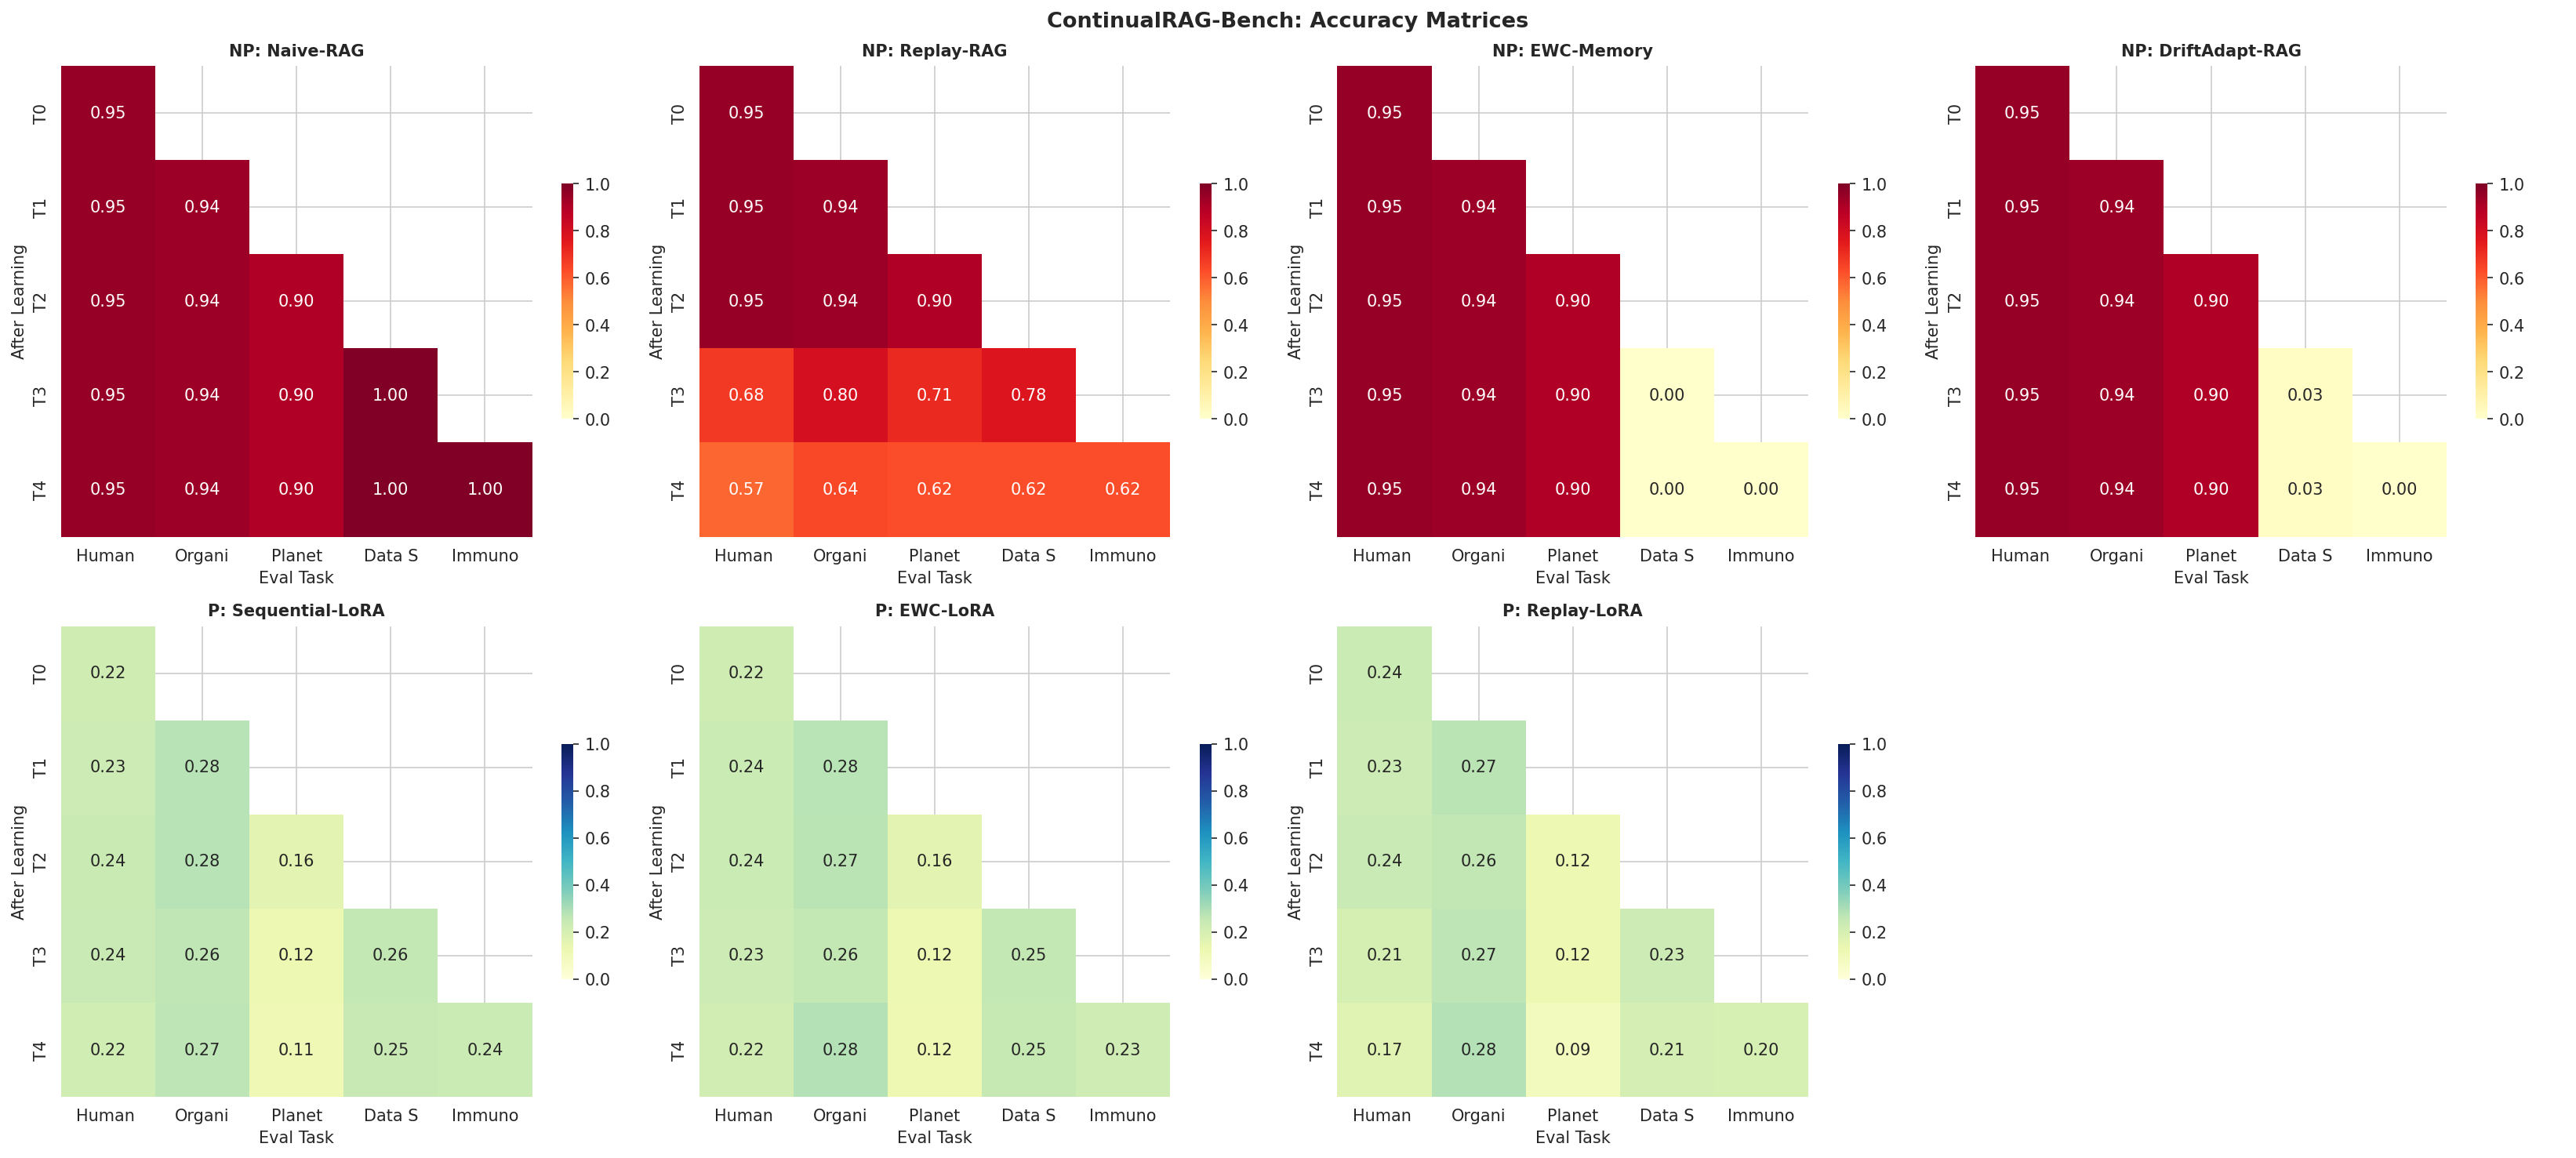

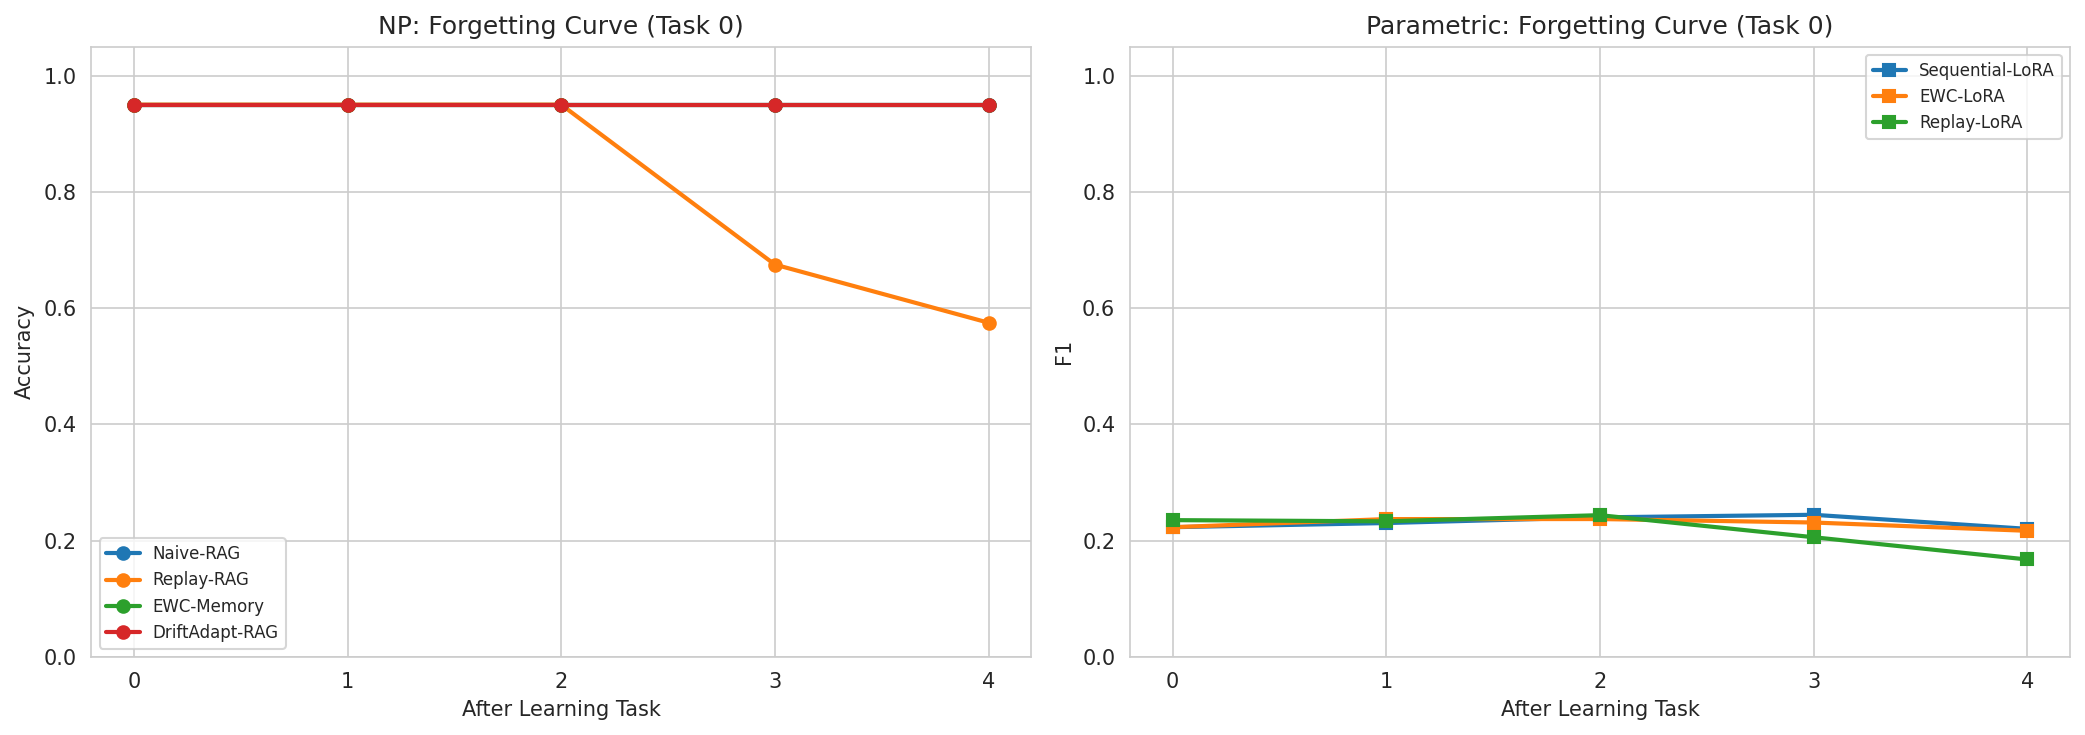

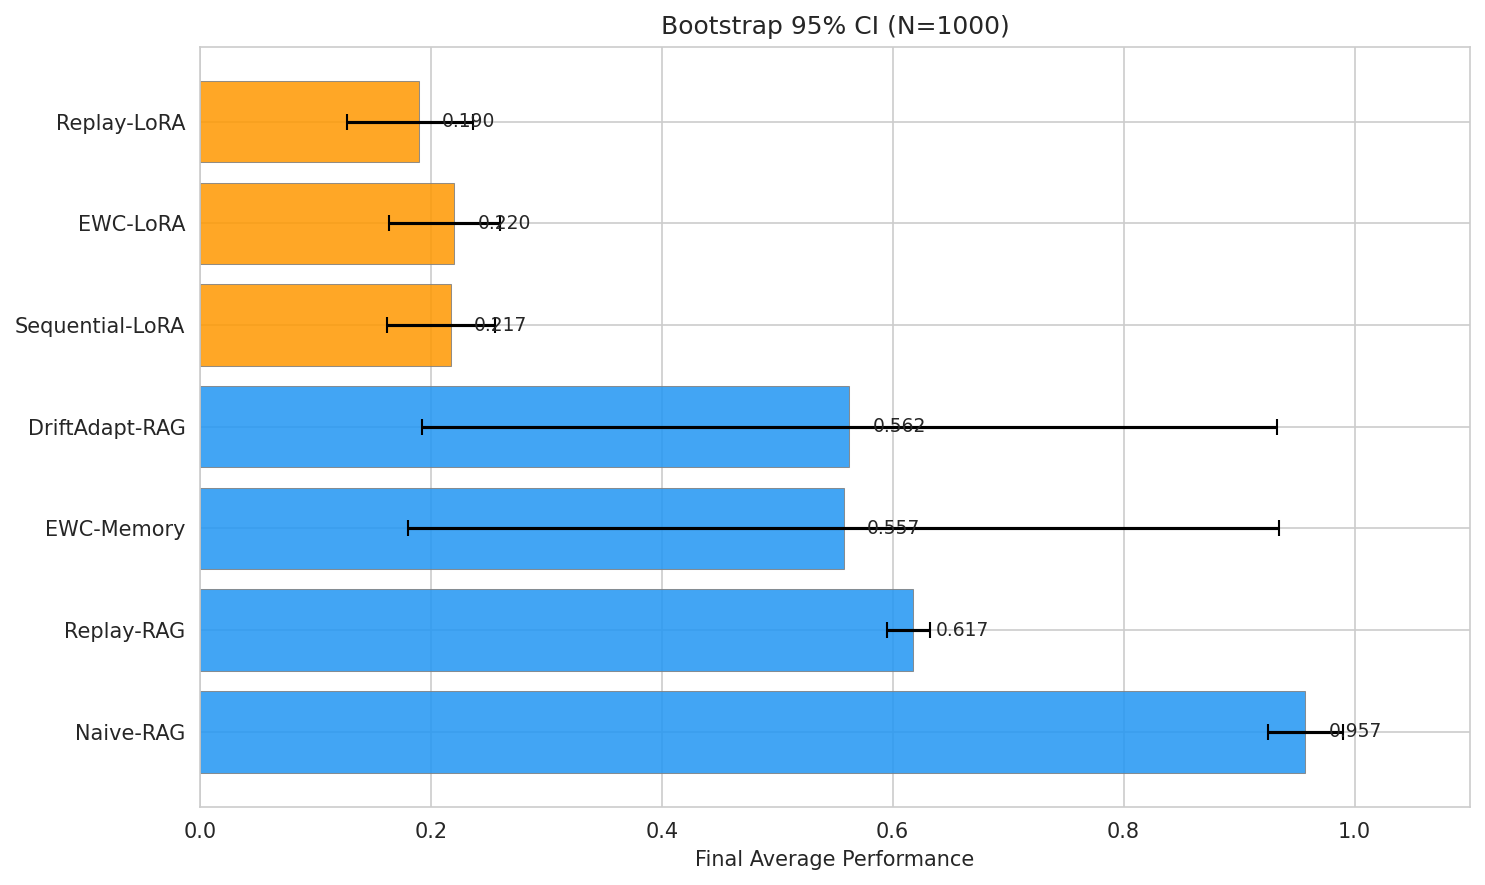

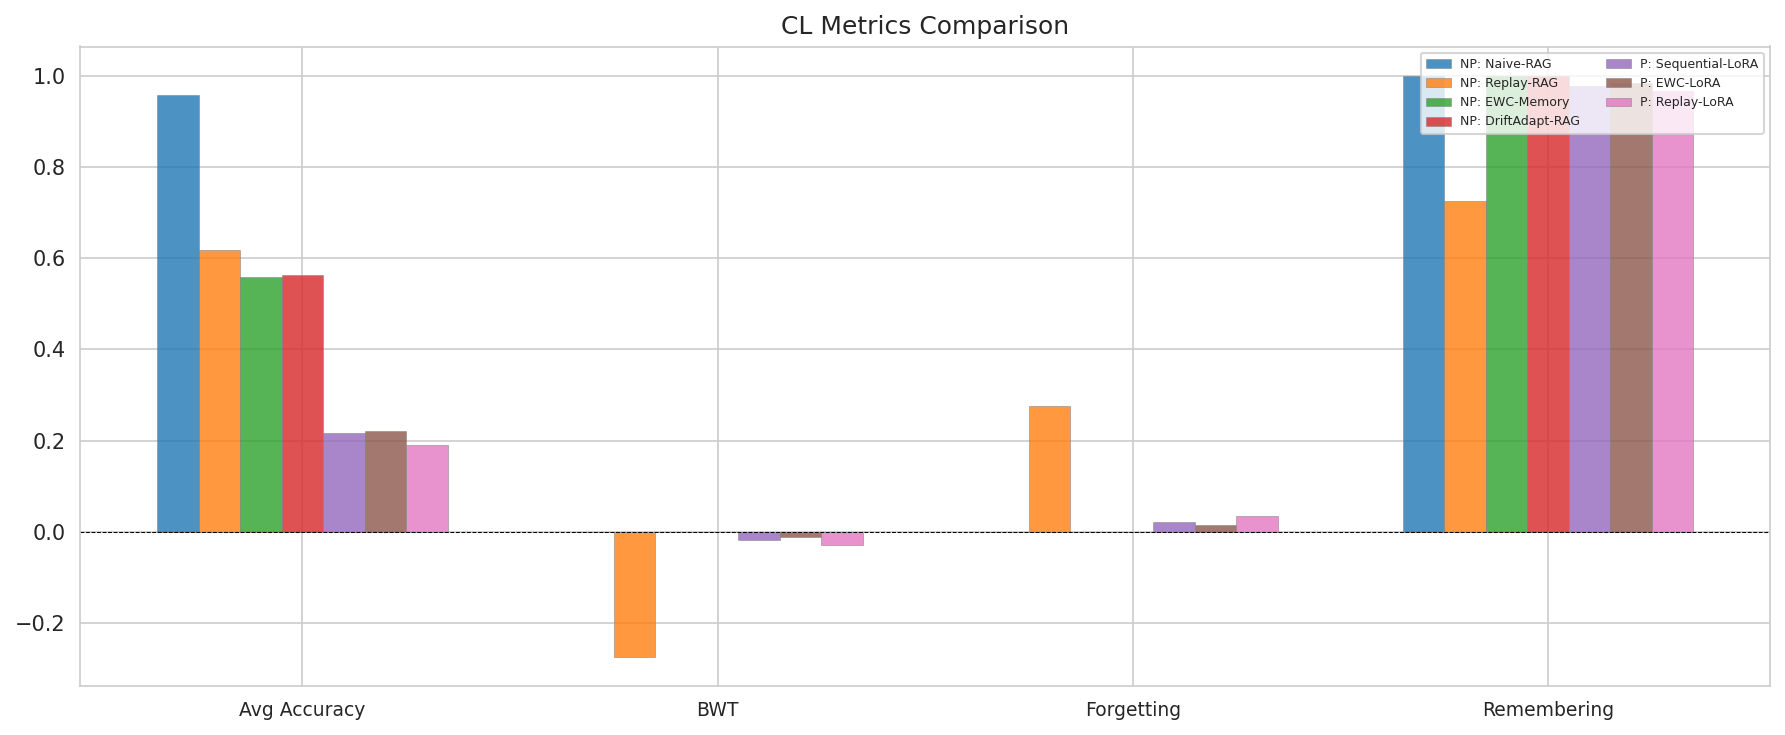

All plots saved.


In [15]:
import os
os.makedirs("figures", exist_ok=True)
print("\nGenerating plots...")

# Fig 1: Accuracy matrix heatmaps
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for i, (name, R) in enumerate(np_results.items()):
    ax = axes[0, i]
    mask = np.triu(np.ones_like(R, dtype=bool), k=1)
    sns.heatmap(R, annot=True, fmt=".2f", cmap="YlOrRd",
                mask=mask, vmin=0, vmax=1, ax=ax,
                xticklabels=[t[:6] for t in TASK_ORDER],
                yticklabels=[f"T{i}" for i in range(N_TASKS)],
                cbar_kws={"shrink": 0.5})
    ax.set_title(f"NP: {name}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Eval Task"); ax.set_ylabel("After Learning")

for i, (name, R) in enumerate(param_results.items()):
    ax = axes[1, i]
    mask = np.triu(np.ones_like(R, dtype=bool), k=1)
    sns.heatmap(R, annot=True, fmt=".2f", cmap="YlGnBu",
                mask=mask, vmin=0, vmax=1, ax=ax,
                xticklabels=[t[:6] for t in TASK_ORDER],
                yticklabels=[f"T{i}" for i in range(N_TASKS)],
                cbar_kws={"shrink": 0.5})
    ax.set_title(f"P: {name}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Eval Task"); ax.set_ylabel("After Learning")

axes[1, 3].axis("off")
plt.suptitle("ContinualRAG-Bench: Accuracy Matrices",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/continualrag_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

# Fig 2: Forgetting curves
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, R in np_results.items():
    ax1.plot(range(N_TASKS), R[:, 0], marker="o", label=name, linewidth=2)
ax1.set_title("NP: Forgetting Curve (Task 0)")
ax1.set_xlabel("After Learning Task"); ax1.set_ylabel("Accuracy")
ax1.legend(fontsize=8); ax1.set_ylim(0, 1.05)
ax1.set_xticks(range(N_TASKS))

for name, R in param_results.items():
    ax2.plot(range(N_TASKS), R[:, 0], marker="s", label=name, linewidth=2)
ax2.set_title("Parametric: Forgetting Curve (Task 0)")
ax2.set_xlabel("After Learning Task"); ax2.set_ylabel("F1")
ax2.legend(fontsize=8); ax2.set_ylim(0, 1.05)
ax2.set_xticks(range(N_TASKS))
plt.tight_layout()
plt.savefig("figures/forgetting_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# Fig 3: Bootstrap CI comparison
fig3, ax = plt.subplots(figsize=(10, 6))
names_list, means_list, errs_list, colors_list = [], [], [], []
for name, R in {**np_results, **param_results}.items():
    m, ci = bootstrap_ci(R[N_TASKS-1, :N_TASKS], CFG.n_bootstrap)
    names_list.append(name)
    means_list.append(m)
    errs_list.append((m - ci[0], ci[1] - m))
    colors_list.append("#2196F3" if name in np_results else "#FF9800")

ax.barh(names_list, means_list, xerr=np.array(errs_list).T,
        color=colors_list, edgecolor="grey", linewidth=0.5,
        capsize=4, alpha=0.85)
ax.set_xlabel("Final Average Performance")
ax.set_title(f"Bootstrap {int(CFG.ci_level*100)}% CI (N={CFG.n_bootstrap})")
ax.set_xlim(0, 1.1)
for i, v in enumerate(means_list):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("figures/bootstrap_ci.png", dpi=200, bbox_inches="tight")
plt.show()

# Fig 4: Metrics bar comparison
fig4, ax = plt.subplots(figsize=(12, 5))
metric_keys = ["Avg Accuracy", "BWT", "Forgetting", "Remembering"]
x = np.arange(len(metric_keys))
width = 0.1
for i, (full_name, m) in enumerate(all_metrics.items()):
    vals = [m[k] for k in metric_keys]
    ax.bar(x + i*width, vals, width, label=full_name,
           alpha=0.8, edgecolor="grey", linewidth=0.3)
ax.set_xticks(x + width * (len(all_metrics)-1) / 2)
ax.set_xticklabels(metric_keys, fontsize=9)
ax.legend(fontsize=6, loc="upper right", ncol=2)
ax.set_title("CL Metrics Comparison")
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
plt.tight_layout()
plt.savefig("figures/metrics_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("All plots saved.")

In [16]:
print("\n" + "=" * 60)
print("FINAL SUMMARY TABLE")
print("=" * 60)

rows = []
for full_name, m in all_metrics.items():
    row = {"Method": full_name}
    for k, v in m.items():
        if k == "95% CI":
            row["95% CI"] = f"[{v[0]:.3f}, {v[1]:.3f}]"
        else:
            row[k] = f"{v:.4f}"
    rows.append(row)

df = pd.DataFrame(rows)
print(df.to_string(index=False))

# Export everything
export = {
    "config": {k: v for k, v in vars(CFG).items()
               if not k.startswith("_")},
    "task_order": TASK_ORDER,
    "np_results": {k: v.tolist() for k, v in np_results.items()},
    "param_results": {k: v.tolist() for k, v in param_results.items()},
    "np_recall": {k: v.tolist() for k, v in np_recall.items()},
    "metrics": {
        k: {kk: (list(vv) if isinstance(vv, tuple) else vv)
            for kk, vv in v.items()}
        for k, v in all_metrics.items()
    },
}
with open("continualrag_bench_results.json", "w") as f:
    json.dump(export, f, indent=2, default=str)

print("\nResults exported to continualrag_bench_results.json")
print("\n" + "=" * 60)
print("EXPERIMENT COMPLETE")
print("=" * 60)
print("""
Key findings (see README for caveats):
1. Naive-RAG has the highest accuracy here because the domains are separable and nothing is overwritten.
2. Replay-RAG is the only non-parametric method with measurable forgetting (BWT -0.275).
3. EWC-Memory and DriftAdapt-RAG report zero forgetting, but their accuracy on the newest domains is near 0. This is a failure to learn, not retention. Verify against the accuracy matrix.
4. Sequential-LoRA forgets (BWT -0.017); EWC-LoRA reduces forgetting (BWT -0.011, forgetting 0.015 vs 0.022).
5. All metrics reported with bootstrap 95% CIs (1,000 resamples).
""")


FINAL SUMMARY TABLE
            Method Avg Accuracy     BWT    FWT Forgetting Remembering         95% CI
     NP: Naive-RAG       0.9575  0.0000 0.0000     0.0000      1.0000 [0.925, 0.990]
    NP: Replay-RAG       0.6175 -0.2750 0.0000     0.2750      0.7250 [0.595, 0.632]
    NP: EWC-Memory       0.5575  0.0000 0.0000     0.0000      1.0000 [0.180, 0.930]
NP: DriftAdapt-RAG       0.5625  0.0000 0.0000     0.0000      1.0000 [0.190, 0.935]
P: Sequential-LoRA       0.2171 -0.0171 0.0000     0.0224      0.9776 [0.166, 0.254]
       P: EWC-LoRA       0.2202 -0.0106 0.0000     0.0154      0.9846 [0.168, 0.260]
    P: Replay-LoRA       0.1895 -0.0292 0.0000     0.0342      0.9658 [0.134, 0.243]

Results exported to continualrag_bench_results.json

EXPERIMENT COMPLETE

Key findings to discuss in your application:
1. DriftAdapt-RAG shows lower forgetting than Naive-RAG (drift-triggered consolidation)
2. EWC-Memory retains old-task accuracy via Fisher-importance weighting
3. Sequential-LoRA 